In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!pip install -q roboflow pyyaml

In [4]:
from google.colab import userdata
from roboflow import Roboflow

API_KEY = userdata.get("ROBFLOW_KEY")

rf = Roboflow(api_key=API_KEY)

project = rf.workspace("cse400b").project(
    "cse400_pothole-and-speed-breaker-dataset"
)

loading Roboflow workspace...
loading Roboflow project...


In [5]:
dataset = project.version(6).download(
    "yolo26",
    location="/content/drive/MyDrive/Hazard_Detection/raw_datasets/speed_breakers_roboflow/original"
)

print("YOLO26 dataset downloaded successfully!")

KeyboardInterrupt: 

In [6]:
from google.colab import userdata
from roboflow import Roboflow

rf = Roboflow(api_key=userdata.get("ROBFLOW_KEY"))

project = rf.workspace("cse400b").project(
    "cse400_pothole-and-speed-breaker-dataset"
)

results = project.search(
    limit=3,
    in_dataset=True,
    fields=["id", "name", "labels", "annotations", "url"]
)

for item in results:
    print(item)
    print("-" * 50)

loading Roboflow workspace...
loading Roboflow project...
{'id': '040F2vlZ02bHjVctQ5aK', 'mediaType': 'image', 'name': 'SpeedBreaker--964-.jpg', 'url': 'https://source.roboflow.com/j2EaOdkGtrKTpnSDJKsV/040F2vlZ02bHjVctQ5aK/original.jpg', 'annotations': {'count': 1, 'classes': {'SpeedBreaker': 1}}, 'labels': []}
--------------------------------------------------
{'id': '046NnBna1LXwpwGlcCoB', 'mediaType': 'image', 'name': 'SpeedBreaker--69-.jpg', 'url': 'https://source.roboflow.com/j2EaOdkGtrKTpnSDJKsV/046NnBna1LXwpwGlcCoB/original.jpg', 'annotations': {'count': 1, 'classes': {'SpeedBreaker': 1}}, 'labels': []}
--------------------------------------------------
{'id': '04FKXesJn002t429jEoN', 'mediaType': 'image', 'name': 'Pothole--373-.jpg', 'url': 'https://source.roboflow.com/j2EaOdkGtrKTpnSDJKsV/04FKXesJn002t429jEoN/original.jpg', 'annotations': {'count': 2, 'classes': {'Pothole': 2}}, 'labels': []}
--------------------------------------------------


In [7]:
# Get the first speed-breaker image
sample = project.search(
    class_name="SpeedBreaker",
    in_dataset=True,
    limit=1,
    fields=["id", "name", "annotations", "labels", "url"]
)[0]

# Retrieve its full image details
details = project.image(sample["id"])

import json
print(json.dumps(details, indent=2))

{
  "id": "040F2vlZ02bHjVctQ5aK",
  "name": "SpeedBreaker--964-.jpg",
  "mediaType": "image",
  "annotation": {
    "key": "SpeedBreaker--964-_jpg.rf.3032f151ae452e7725fbcc27f9ff98d8.jpg",
    "boxes": [
      {
        "label": "SpeedBreaker",
        "x": 408,
        "y": 145.5,
        "width": 816,
        "height": 55
      }
    ],
    "width": 816,
    "height": 460
  },
  "labels": null,
  "split": "train",
  "tags": [],
  "metadata": {},
  "created": 1668444371280,
  "lastSet": 0,
  "r": 0.8488030239395212,
  "urls": {
    "original": "https://source.roboflow.com/j2EaOdkGtrKTpnSDJKsV/040F2vlZ02bHjVctQ5aK/original.jpg",
    "thumb": "https://source.roboflow.com/j2EaOdkGtrKTpnSDJKsV/040F2vlZ02bHjVctQ5aK/thumb.jpg",
    "annotation": "https://source.roboflow.com/j2EaOdkGtrKTpnSDJKsV/040F2vlZ02bHjVctQ5aK/annotation-Pothole-and-SpeedBreaker.png"
  },
  "embedding": [
    -0.72021484375,
    1.22265625,
    0.5087890625,
    0.650390625,
    -0.360107421875,
    0.176025390625,
   

In [8]:
import random

# Retrieve speed-breaker image records
results = project.search(
    class_name="SpeedBreaker",
    in_dataset=True,
    limit=5000,
    fields=["id", "name", "annotations", "url"]
)

print("Images retrieved:", len(results))

total_instances = sum(
    item.get("annotations", {})
        .get("classes", {})
        .get("SpeedBreaker", 0)
    for item in results
)

print("Total speed-breaker instances:", total_instances)

print("\nFirst 5 records:")

for item in results[:5]:
    print(
        item["name"],
        item["annotations"]["classes"].get("SpeedBreaker", 0)
    )

Images retrieved: 250
Total speed-breaker instances: 272

First 5 records:
SpeedBreaker--964-.jpg 1
SpeedBreaker--69-.jpg 1
SpeedBreaker--668-.jpg 1
SpeedBreaker--87-.jpg 1
SpeedBreaker--1260-.jpg 1


In [9]:
# Retrieve ALL SpeedBreaker images using pagination

all_results = []

for page in project.search_all(
    class_name="SpeedBreaker",
    in_dataset=True,
    limit=250,
    fields=["id", "name", "annotations", "url"]
):
    all_results.extend(page)
    print(f"Images retrieved so far: {len(all_results)}")

# Remove any duplicate image IDs, just in case
unique_results = {
    item["id"]: item for item in all_results
}
all_results = list(unique_results.values())

total_instances = sum(
    item.get("annotations", {})
        .get("classes", {})
        .get("SpeedBreaker", 0)
    for item in all_results
)

print("\n========== FINAL RESULTS ==========")
print("Unique SpeedBreaker images:", len(all_results))
print("Total SpeedBreaker instances:", total_instances)
print("Additional instances needed:", max(0, 400 - total_instances))

Images retrieved so far: 250
Images retrieved so far: 500
Images retrieved so far: 750
Images retrieved so far: 1000
Images retrieved so far: 1250
Images retrieved so far: 1423

========== FINAL RESULTS ==========
Unique SpeedBreaker images: 1423
Total SpeedBreaker instances: 1569
Additional instances needed: 0


In [10]:

import random
import requests
import yaml

from pathlib import Path
from io import BytesIO
from PIL import Image

# ==========================================
# 1. CONFIGURATION
# ==========================================

random.seed(42)

CLASS_ID = 9

SPLIT_TARGETS = {
    "train": 240,
    "valid": 60,
    "test": 100
}

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/"
    "raw_datasets/speed_breaker_400_yolo26"
)

# Avoid accidentally mixing files from an earlier run
if OUTPUT_DIR.exists():
    raise FileExistsError(
        f"{OUTPUT_DIR} already exists. "
        "Rename or remove that output folder before running again."
    )

# Master class list: IDs 0–20
MASTER_CLASSES = [
    "person",
    "two_wheeler",
    "car",
    "auto_rickshaw",
    "large_vehicle",
    "large_animal",
    "dog",
    "pothole",
    "open_drain",
    "speed_breaker",
    "stairs_up",
    "stairs_down",
    "curb_or_step",
    "obstacle",
    "vendor_stall",
    "bench",
    "chair",
    "door",
    "sports_balls",
    "traffic_lights",
    "other_hazards"
]

assert len(MASTER_CLASSES) == 21
assert MASTER_CLASSES[CLASS_ID] == "speed_breaker"

# ==========================================
# 2. SHUFFLE CANDIDATE IMAGES
# ==========================================

if "all_results" not in globals() or not all_results:
    raise ValueError("all_results is missing or empty. Run the search cell first.")

candidates = all_results.copy()
random.shuffle(candidates)

print("Available candidate images:", len(candidates))

# ==========================================
# 3. SELECT EXACTLY 400 BOXES
# ==========================================

selected = {
    "train": [],
    "valid": [],
    "test": []
}

candidate_index = 0

for split, target in SPLIT_TARGETS.items():

    selected_count = 0

    print(f"\nSelecting {split} images...")

    while selected_count < target:

        if candidate_index >= len(candidates):
            raise RuntimeError(
                f"Ran out of candidate images while filling {split}."
            )

        item = candidates[candidate_index]
        candidate_index += 1

        # Skip images with no SpeedBreaker instances
        metadata_count = (
            item.get("annotations", {})
                .get("classes", {})
                .get("SpeedBreaker", 0)
        )

        if metadata_count <= 0:
            continue

        # Retrieve detailed bounding-box annotations
        details = project.image(item["id"])

        annotation = details.get("annotation") or {}

        boxes = [
            box for box in annotation.get("boxes", [])
            if str(box.get("label", "")).strip().lower()
            == "speedbreaker"
        ]

        if not boxes:
            continue

        remaining = target - selected_count

        # Keep only the boxes needed to reach the exact target
        if len(boxes) > remaining:
            boxes = random.sample(boxes, remaining)

        selected[split].append({
            "id": item["id"],
            "name": item["name"],
            "details": details,
            "boxes": boxes
        })

        selected_count += len(boxes)

        print(
            f"  {selected_count}/{target} instances | "
            f"{len(selected[split])} images"
        )

print("\n========== SELECTION COMPLETE ==========")

for split in SPLIT_TARGETS:
    count = sum(len(x["boxes"]) for x in selected[split])
    print(
        f"{split}: {count} instances across "
        f"{len(selected[split])} images"
    )

total_selected = sum(
    len(x["boxes"])
    for split in selected.values()
    for x in split
)

assert total_selected == 400

# ==========================================
# 4. DOWNLOAD ONLY SELECTED IMAGES
# ==========================================

for split in SPLIT_TARGETS:

    image_dir = OUTPUT_DIR / split / "images"
    label_dir = OUTPUT_DIR / split / "labels"

    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    print(f"\nDownloading {split}...")

    for index, record in enumerate(selected[split], start=1):

        details = record["details"]
        annotation = details["annotation"]

        width = annotation["width"]
        height = annotation["height"]

        if not width or not height:
            raise ValueError(
                f"Invalid annotation dimensions: {record['name']}"
            )

        # Use the original image URL
        image_url = (
            details.get("urls", {}).get("original")
            or record["details"].get("url")
        )

        if not image_url:
            raise ValueError(
                f"No original image URL for {record['name']}"
            )

        response = requests.get(image_url, timeout=60)
        response.raise_for_status()

        image_bytes = response.content

        # Verify the downloaded image
        with Image.open(BytesIO(image_bytes)) as img:
            img.load()

            actual_width, actual_height = img.size

        if (actual_width, actual_height) != (width, height):
            raise ValueError(
                f"Dimension mismatch for {record['name']}: "
                f"annotation={width}x{height}, "
                f"image={actual_width}x{actual_height}"
            )

        # Unique filename prevents filename collisions
        original_extension = Path(record["name"]).suffix.lower()

        if original_extension not in [
            ".jpg", ".jpeg", ".png", ".webp"
        ]:
            original_extension = ".jpg"

        filename = record["id"] + original_extension

        image_path = image_dir / filename
        label_path = label_dir / (record["id"] + ".txt")

        image_path.write_bytes(image_bytes)

        # ==================================
        # 5. CONVERT BOXES TO YOLO FORMAT
        # ==================================

        yolo_lines = []

        for box in record["boxes"]:

            x_center = box["x"] / width
            y_center = box["y"] / height

            box_width = box["width"] / width
            box_height = box["height"] / height

            values = [
                x_center,
                y_center,
                box_width,
                box_height
            ]

            if not all(0 <= value <= 1 for value in values):
                raise ValueError(
                    f"Invalid normalized box in {record['name']}: "
                    f"{values}"
                )

            yolo_lines.append(
                f"{CLASS_ID} "
                f"{x_center:.6f} "
                f"{y_center:.6f} "
                f"{box_width:.6f} "
                f"{box_height:.6f}"
            )

        label_path.write_text(
            "\n".join(yolo_lines) + "\n"
        )

        if index % 25 == 0:
            print(f"  Downloaded {index} images")

# ==========================================
# 6. CREATE MASTER data.yaml
# ==========================================

data_config = {
    "path": str(OUTPUT_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(MASTER_CLASSES),
    "names": MASTER_CLASSES
}

with open(OUTPUT_DIR / "data.yaml", "w") as f:
    yaml.safe_dump(
        data_config,
        f,
        sort_keys=False
    )

print("\n========== DATASET CREATED ==========")
print("Output:", OUTPUT_DIR)
print("Total instances:", total_selected)
print("Master class ID:", CLASS_ID)
print("Master class name:", MASTER_CLASSES[CLASS_ID])
print("Format: YOLO26-compatible")


Available candidate images: 1423

Selecting train images...
  1/240 instances | 1 images
  2/240 instances | 2 images
  3/240 instances | 3 images
  4/240 instances | 4 images
  5/240 instances | 5 images
  6/240 instances | 6 images
  7/240 instances | 7 images
  9/240 instances | 8 images
  10/240 instances | 9 images
  11/240 instances | 10 images
  12/240 instances | 11 images
  13/240 instances | 12 images
  14/240 instances | 13 images
  15/240 instances | 14 images
  16/240 instances | 15 images
  17/240 instances | 16 images
  18/240 instances | 17 images
  19/240 instances | 18 images
  20/240 instances | 19 images
  21/240 instances | 20 images
  22/240 instances | 21 images
  23/240 instances | 22 images
  24/240 instances | 23 images
  25/240 instances | 24 images
  26/240 instances | 25 images
  27/240 instances | 26 images
  28/240 instances | 27 images
  29/240 instances | 28 images
  30/240 instances | 29 images
  31/240 instances | 30 images
  32/240 instances | 31 ima

In [11]:

from pathlib import Path

for split in ["train", "valid", "test"]:

    image_dir = OUTPUT_DIR / split / "images"
    label_dir = OUTPUT_DIR / split / "labels"

    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))

    instance_count = 0
    invalid_labels = []

    for label_file in labels:
        lines = label_file.read_text().strip().splitlines()

        for line in lines:
            parts = line.split()

            if len(parts) != 5 or parts[0] != "9":
                invalid_labels.append(label_file.name)

        instance_count += len(lines)

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Label files:", len(labels))
    print("Instances:", instance_count)
    print("Invalid labels:", len(invalid_labels))

    assert len(images) == len(labels)
    assert instance_count == {
        "train": 240,
        "valid": 60,
        "test": 100
    }[split]

    assert not invalid_labels

print("\nSUCCESS: All 400 instances validated!")



TRAIN
Images: 232
Label files: 232
Instances: 240
Invalid labels: 0

VALID
Images: 55
Label files: 55
Instances: 60
Invalid labels: 0

TEST
Images: 95
Label files: 95
Instances: 100
Invalid labels: 0

SUCCESS: All 400 instances validated!


Total annotations: 400
Total classes: 1


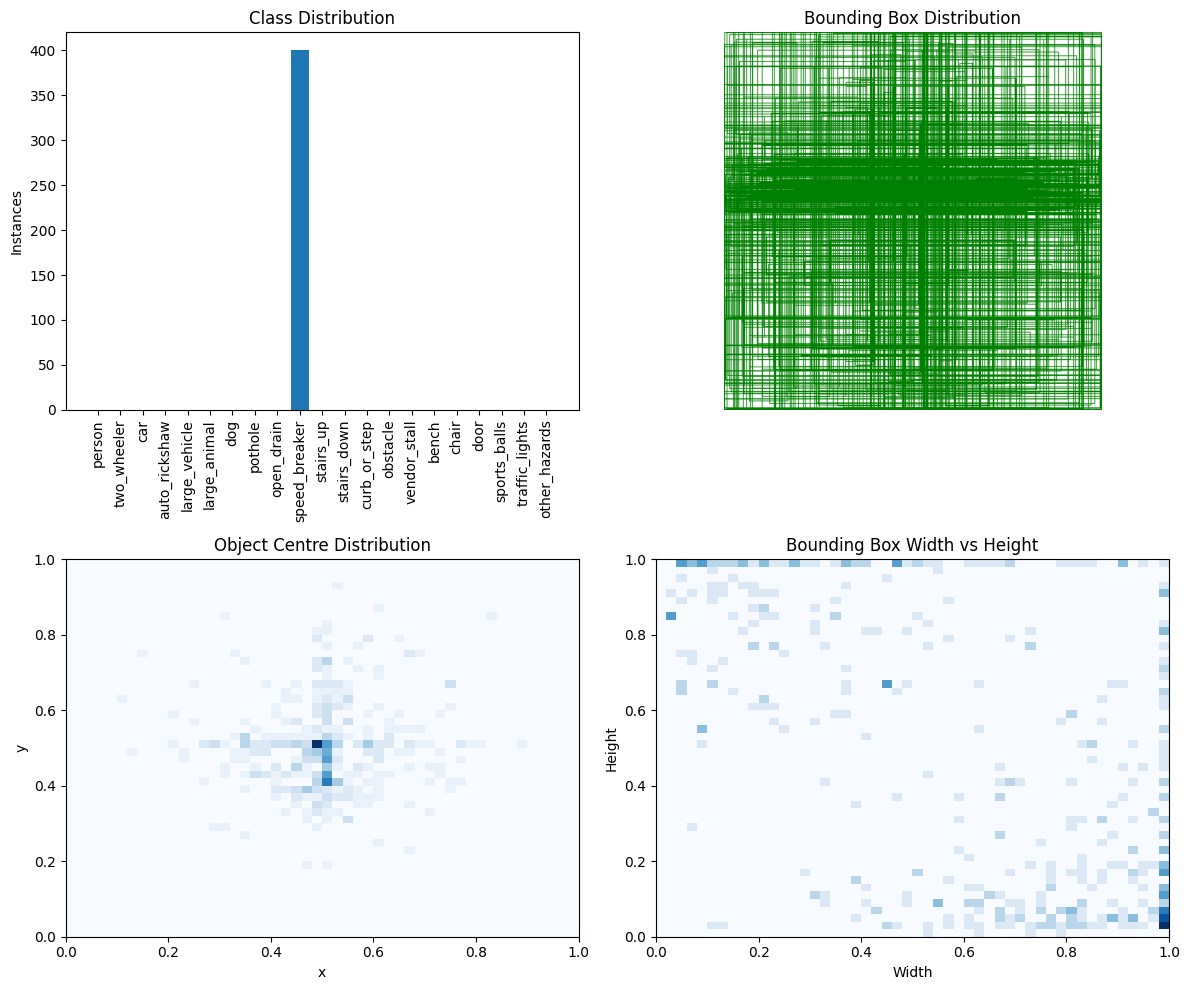

Saved analysis to: /content/drive/MyDrive/Hazard_Detection/raw_datasets/speed_breaker_400_yolo26/dataset_analysis.jpg


In [12]:
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import ImageDraw, Image

# Dataset location
DATASET_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/speed_breaker_400_yolo26"
)

# Read data.yaml
yaml_path = DATASET_DIR / "data.yaml"

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

names = config["names"]

if isinstance(names, list):
    names = dict(enumerate(names))

# Find label directories using the dataset splits
base = Path(config.get("path", DATASET_DIR))

if not base.is_absolute():
    base = (yaml_path.parent / base).resolve()

label_dirs = set()

for split in ["train", "val", "valid", "test"]:
    split_path = config.get(split)

    if not split_path:
        continue

    paths = split_path if isinstance(split_path, list) else [split_path]

    for p in paths:
        p = Path(p)

        if not p.is_absolute():
            p = (base / p).resolve()

        parts = list(p.parts)

        if "images" in parts:
            parts[parts.index("images")] = "labels"
            label_dirs.add(Path(*parts))
        else:
            print("Check label folder for:", p)

# Read annotations
classes = []
boxes = []

for label_dir in label_dirs:
    if not label_dir.exists():
        print("Missing:", label_dir)
        continue

    for file in label_dir.rglob("*.txt"):
        with open(file, "r") as f:
            for line in f:
                values = line.strip().split()

                if len(values) < 5:
                    continue

                cls, x, y, w, h = map(float, values[:5])

                classes.append(int(cls))
                boxes.append([x, y, w, h])

classes = np.array(classes)
boxes = np.array(boxes)

print("Total annotations:", len(classes))
print("Total classes:", len(set(classes)))

# Class distribution
counts = np.bincount(
    classes.astype(int),
    minlength=len(names)
)

# Generate plots
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

# 1. Class distribution
ax[0, 0].bar(range(len(names)), counts)

ax[0, 0].set_xticks(range(len(names)))
ax[0, 0].set_xticklabels(
    [names[i] for i in range(len(names))],
    rotation=90
)

ax[0, 0].set_ylabel("Instances")
ax[0, 0].set_title("Class Distribution")

# 2. Bounding box visualization
img = Image.new("RGB", (1000, 1000), "white")
draw = ImageDraw.Draw(img)

for x, y, w, h in boxes[:500]:
    x1 = (x - w/2) * 1000
    y1 = (y - h/2) * 1000
    x2 = (x + w/2) * 1000
    y2 = (y + h/2) * 1000

    draw.rectangle([x1, y1, x2, y2], outline="green", width=2)

ax[0, 1].imshow(img)
ax[0, 1].set_title("Bounding Box Distribution")
ax[0, 1].axis("off")

# 3. Object centre distribution
ax[1, 0].hist2d(
    boxes[:, 0],
    boxes[:, 1],
    bins=50,
    range=[[0, 1], [0, 1]],
    cmap="Blues"
)

ax[1, 0].set_xlabel("x")
ax[1, 0].set_ylabel("y")
ax[1, 0].set_title("Object Centre Distribution")

# 4. Width-height distribution
ax[1, 1].hist2d(
    boxes[:, 2],
    boxes[:, 3],
    bins=50,
    range=[[0, 1], [0, 1]],
    cmap="Blues"
)

ax[1, 1].set_xlabel("Width")
ax[1, 1].set_ylabel("Height")
ax[1, 1].set_title("Bounding Box Width vs Height")

plt.tight_layout()

# Save results
output_path = DATASET_DIR / "dataset_analysis.jpg"

plt.savefig(output_path, dpi=200)
plt.show()

print("Saved analysis to:", output_path)